# Task 4.12 — Sweep over S and overlap $c$, with a stopping criterion

In [1]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from functools import reduce, lru_cache

np.random.seed(0)

PSI_OFFSET = np.pi / 2  # |psi> = RY(pi/2)|0>, generic state (not aligned with the computational basis)
NOISE_TYPES = ["depolarizing", "dephasing"]


def delta_from_c(c):
    return 2 * np.arccos(np.sqrt(c))  # |phi> = RY(pi/2 + delta)|0>  =>  overlap c = cos^2(delta/2)

## 2. Optimal measurement engine (scalable version)

- $\hat J^2 = \tfrac{3n}{4} - \tfrac{n(n-1)}{4} + \sum_{i<j}\mathrm{SWAP}_{ij}$ (with $n=2S$ qubits) commutes with the total $\hat J_z$, so it is block-diagonal in the Hamming-weight sectors of the computational basis. We diagonalize each block separately (largest block: $\binom{12}{6}=924$ for $S=6$).
- Both noise channels act independently on each qubit, so the noisy state is a **product of single-qubit density matrices** (one for each copy of $|\psi\rangle$ and one for each copy of $|\phi\rangle$). Each single-qubit noisy state is obtained with PennyLane (`default.mixed`).
- $\Pi_J$ is block-diagonal in the same sectors, so $p(J)=\sum_k \mathrm{Tr}[\Pi_J^{(k)}\rho_{kk}]$ only needs the diagonal blocks $\rho_{kk}$ of the product state.

Section 3 validates this engine against the dense method used before.

In [2]:
_sector_cache = {}


def sector_data(n):
    """Hamming-weight sectors of J^2 for n qubits; eigenvectors labelled by the total angular momentum J."""
    if n in _sector_cache:
        return _sector_cache[n]
    all_states = np.arange(2 ** n)
    shifts = np.arange(n - 1, -1, -1)
    bits = ((all_states[:, None] >> shifts) & 1).astype(np.int8)  # qubit 0 = most significant bit
    popcount = bits.sum(axis=1)
    base = 3 * n / 4 - n * (n - 1) / 4
    sectors = []
    for k in range(n + 1):
        states = np.where(popcount == k)[0]
        bits_k = bits[states]
        dim = len(states)
        H = np.zeros((dim, dim))
        H[np.arange(dim), np.arange(dim)] = base
        for i in range(n):
            for j in range(i + 1, n):
                equal = bits_k[:, i] == bits_k[:, j]
                eq_idx = np.where(equal)[0]
                H[eq_idx, eq_idx] += 1.0              # SWAP_ij acts as identity if the two bits are equal
                diff_idx = np.where(~equal)[0]
                if len(diff_idx):                      # ...and flips both bits if they differ
                    flip = (1 << (n - 1 - i)) | (1 << (n - 1 - j))
                    j2 = np.searchsorted(states, states[diff_idx] ^ flip)
                    H[diff_idx, j2] += 1.0
        w, V = np.linalg.eigh(H)
        J = np.round(2 * (-1 + np.sqrt(1 + 4 * np.clip(w, 0, None))) / 2) / 2  # J(J+1) -> J, nearest half-integer
        sectors.append({"bits": bits_k, "V": V, "J": J})
    _sector_cache[n] = sectors
    return sectors


@lru_cache(maxsize=None)
def single_qubit_state(angle, p, noise_type):
    """Noisy single-qubit density matrix RY(angle)|0> followed by the noise channel (PennyLane)."""
    dev = qml.device("default.mixed", wires=1)

    @qml.qnode(dev)
    def circuit():
        qml.RY(angle, wires=0)
        if p > 0:
            if noise_type == "depolarizing":
                qml.DepolarizingChannel(p, wires=0)
            else:
                qml.PhaseFlip(p, wires=0)
        return qml.density_matrix(wires=0)

    return np.real(np.array(circuit()))


def J_distribution(c, S, p, noise_type):
    """p(J) for N=M=S copies of |psi>, |phi> with overlap c, under per-qubit noise of strength p."""
    n = 2 * S
    delta = delta_from_c(c)
    R_psi = single_qubit_state(PSI_OFFSET, p, noise_type)
    R_phi = single_qubit_state(PSI_OFFSET + delta, p, noise_type)
    probs = {}
    for sec in sector_data(n):
        bits_k, V = sec["bits"], sec["V"]
        dim = bits_k.shape[0]
        rho = np.ones((dim, dim))                      # diagonal block rho_kk of the product state
        for i in range(n):
            R = R_psi if i < S else R_phi
            b = bits_k[:, i]
            rho *= R[b[:, None], b[None, :]]
        q = np.sum(V * (rho @ V), axis=0)              # <v|rho|v> for every eigenvector in the sector
        for Jval, qv in zip(sec["J"], q):
            probs[Jval] = probs.get(Jval, 0.0) + float(qv)
    return probs


def optimal_mse(c, S, p, noise_type):
    """MSE of the optimal measurement with the estimator c_hat(J) = (2J/(N+M))^2 (Eq. 8 of the paper)."""
    n = 2 * S
    probs = J_distribution(c, S, p, noise_type)
    return float(sum(pj * ((2 * J / n) ** 2 - c) ** 2 for J, pj in probs.items()))

## 3. Validation against the dense method

The dense reference builds the full $2^{2S}\times2^{2S}$ density matrix with PennyLane and diagonalizes the full $\hat J^2$. Both must agree to numerical precision before we trust the scalable engine for $S=5,6$.

In [3]:
def dense_optimal_mse(c, S, p, noise_type):
    n = 2 * S
    delta = delta_from_c(c)
    dev = qml.device("default.mixed", wires=n)

    @qml.qnode(dev)
    def circuit():
        for i in range(S):
            qml.RY(PSI_OFFSET, wires=i)
        for i in range(S, n):
            qml.RY(PSI_OFFSET + delta, wires=i)
        if p > 0:
            for i in range(n):
                if noise_type == "depolarizing":
                    qml.DepolarizingChannel(p, wires=i)
                else:
                    qml.PhaseFlip(p, wires=i)
        return qml.density_matrix(wires=list(range(n)))

    rho = circuit()
    I2 = np.eye(2, dtype=complex)
    paulis = [np.array([[0, 1], [1, 0]], dtype=complex),
              np.array([[0, -1j], [1j, 0]], dtype=complex),
              np.array([[1, 0], [0, -1]], dtype=complex)]
    dim = 2 ** n
    Jops = [np.zeros((dim, dim), dtype=complex) for _ in range(3)]
    for i in range(n):
        for a, P in enumerate(paulis):
            ops = [I2] * n
            ops[i] = P / 2
            Jops[a] += reduce(np.kron, ops)
    J2 = sum(J @ J for J in Jops)
    w, V = np.linalg.eigh(J2)
    Jv = np.round(2 * (-1 + np.sqrt(1 + 4 * np.clip(w.real, 0, None))) / 2) / 2
    mse = 0.0
    for Jval in np.unique(Jv):
        Vs = V[:, Jv == Jval]
        pj = np.real(np.trace(Vs.conj().T @ rho @ Vs))
        mse += pj * ((2 * Jval / n) ** 2 - c) ** 2
    return float(mse)


max_err = 0.0
for S in [2, 3, 4]:
    for nt in NOISE_TYPES:
        for c, p in [(0.2, 0.0), (0.9, 0.3), (0.5, 0.5), (0.7, 0.12)]:
            max_err = max(max_err, abs(optimal_mse(c, S, p, nt) - dense_optimal_mse(c, S, p, nt)))
print(f"max |scalable - dense| over 24 test points (S=2,3,4): {max_err:.2e}")
assert max_err < 1e-9, "scalable engine does not match the dense reference"
print("Validation passed: the scalable engine is numerically equivalent to the dense method.")

max |scalable - dense| over 24 test points (S=2,3,4): 2.22e-16
Validation passed: the scalable engine is numerically equivalent to the dense method.


## 4. Swap Test MSE

Same circuit as before (ancilla + Hadamard + CSWAP + Hadamard, noise on the two data qubits). The $S$ repetitions are independent, so the exact single-pair probability $p_0$ is computed once with PennyLane and the MSE follows analytically: $\text{MSE}=\text{bias}^2+4p_0(1-p_0)/S$ with the estimator $\hat c = 2\hat p_0-1$ (calibrated for the ideal case).

In [4]:
dev_swap = qml.device("default.mixed", wires=3)


@qml.qnode(dev_swap)
def swap_test_circuit(delta, p_noise, noise_type):
    qml.RY(PSI_OFFSET, wires=2)
    qml.RY(PSI_OFFSET + delta, wires=1)
    if p_noise > 0:
        for w in (1, 2):
            if noise_type == "depolarizing":
                qml.DepolarizingChannel(p_noise, wires=w)
            else:
                qml.PhaseFlip(p_noise, wires=w)
    qml.Hadamard(wires=0)
    qml.CSWAP(wires=[0, 1, 2])
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)


@lru_cache(maxsize=None)
def swap_p0(c, p, noise_type):
    return float(swap_test_circuit(delta_from_c(c), p, noise_type)[0])


def swap_mse(c, S, p, noise_type):
    p0 = swap_p0(c, p, noise_type)
    c_hat = 2 * p0 - 1
    return float((c_hat - c) ** 2 + 4 * p0 * (1 - p0) / S)

## 5. Step (a)+(b): trend of the gap with S (reference point $c=0.2$, noiseless)

At $p=0$ the paper gives a closed-form asymptotic ratio between the two methods for $M=N$: $v_\text{sw}/v_\text{op}\to(1+c)/(2c)$ (Swap Test $v=(1-c^2)/N$ vs. optimal $v=2c(1-c)/N$). For $c=0.2$ that limit is $3.0$, which gives an independent theoretical reference for the trend.

In [5]:
def gap_trend(gaps, tol=1e-3):
    """Classify a sequence of gaps (ordered by increasing S) as growing / stable / shrinking."""
    d = np.diff(gaps)
    if np.any(d < -tol):
        return "SHRINKING"
    if np.all(np.abs(d) <= tol):
        return "stable"
    return "growing"


c_ref = 0.2
asymptote = (1 + c_ref) / (2 * c_ref)
ref_gaps = []
print(f"Reference point: c={c_ref}, p=0 (noiseless).  Asymptotic ratio (1+c)/(2c) = {asymptote:.2f}\n")
print(f"{'S':<4}{'Swap MSE':<12}{'Optimal MSE':<14}{'gap':<8}")
for S in [2, 3, 4]:
    ms, mo = swap_mse(c_ref, S, 0.0, "depolarizing"), optimal_mse(c_ref, S, 0.0, "depolarizing")
    ref_gaps.append(ms / mo)
    print(f"{S:<4}{ms:<12.5f}{mo:<14.5f}{ms / mo:<8.3f}")
print(f"\nTrend of the gap for S=2,3,4 at the reference point: {gap_trend(ref_gaps).upper()}")
print("Rule: growing or stable -> evidence against a crossing at larger S -> stop *for this reference point*.")

Reference point: c=0.2, p=0 (noiseless).  Asymptotic ratio (1+c)/(2c) = 3.00

S   Swap MSE    Optimal MSE   gap     
2   0.48000     0.20600       2.330   
3   0.32000     0.13122       2.439   
4   0.24000     0.09482       2.531   

Trend of the gap for S=2,3,4 at the reference point: GROWING
Rule: growing or stable -> evidence against a crossing at larger S -> stop *for this reference point*.


## 6. Step (c): overlap sweep $c\in[0.1,0.9]$ together with noise, and point-wise stop rule

We sweep $c\in\{0.1,\dots,0.9\}$ and $p\in[0,0.5]$ (21 values) for both channels, for $S=2,3,4$. Then the stop rule of step (b) is applied **at every grid point**: if the gap shrinks from $S=3$ to $S=4$ anywhere, the extension to $S=5,6$ is triggered (and run on the same grid).

In [6]:
c_grid = np.round(np.linspace(0.1, 0.9, 9), 2)
p_grid = np.linspace(0.0, 0.5, 21)

mse_swap = {nt: {} for nt in NOISE_TYPES}
mse_opt = {nt: {} for nt in NOISE_TYPES}


def run_sweep(S_list):
    for S in S_list:
        for nt in NOISE_TYPES:
            ms = np.zeros((len(c_grid), len(p_grid)))
            mo = np.zeros((len(c_grid), len(p_grid)))
            for ic, c in enumerate(c_grid):
                for ip, p in enumerate(p_grid):
                    ms[ic, ip] = swap_mse(float(c), S, float(p), nt)
                    mo[ic, ip] = optimal_mse(float(c), S, float(p), nt)
            mse_swap[nt][S], mse_opt[nt][S] = ms, mo
        print(f"S={S}: sweep done ({len(c_grid)} c x {len(p_grid)} p x {len(NOISE_TYPES)} channels)")


def gap(nt, S):
    return mse_swap[nt][S] / mse_opt[nt][S]


run_sweep([2, 3, 4])

S=2: sweep done (9 c x 21 p x 2 channels)


S=3: sweep done (9 c x 21 p x 2 channels)


S=4: sweep done (9 c x 21 p x 2 channels)


In [7]:
# Point-wise stop rule: does the gap shrink from S=3 to S=4 at some (c, p)?
TOL = 1e-3
trigger_extension = False
print(f"{'noise':<14}{'#points where gap shrinks (S=3->4)':<38}{'c range':<14}{'min p'}")
for nt in NOISE_TYPES:
    shrinking = gap(nt, 4) < gap(nt, 3) * (1 - TOL)
    n_shr = int(shrinking.sum())
    if n_shr:
        trigger_extension = True
        ic, ip = np.where(shrinking)
        print(f"{nt:<14}{n_shr:<38}{c_grid[ic].min():.1f}-{c_grid[ic].max():.1f}{'':<6}{p_grid[ip].min():.3f}")
    else:
        print(f"{nt:<14}{0:<38}{'-':<14}{'-'}")

print()
print("Noiseless (p=0) gap trend S=2->3->4 at every overlap:",
      {float(c): gap_trend([gap('depolarizing', S)[i, 0] for S in (2, 3, 4)]) for i, c in enumerate(c_grid)})
print()
print("EXTEND TO S=5,6 (rule triggered):", trigger_extension)

noise         #points where gap shrinks (S=3->4)    c range       min p
depolarizing  127                                   0.3-0.9      0.000
dephasing     112                                   0.3-0.9      0.000

Noiseless (p=0) gap trend S=2->3->4 at every overlap: {0.1: 'growing', 0.2: 'growing', 0.3: 'SHRINKING', 0.4: 'SHRINKING', 0.5: 'SHRINKING', 0.6: 'SHRINKING', 0.7: 'SHRINKING', 0.8: 'SHRINKING', 0.9: 'SHRINKING'}

EXTEND TO S=5,6 (rule triggered): True


In [8]:
if trigger_extension:
    run_sweep([5, 6])
S_all = sorted(mse_swap["depolarizing"].keys())
print("S values available:", S_all)

S=5: sweep done (9 c x 21 p x 2 channels)


S=6: sweep done (9 c x 21 p x 2 channels)
S values available: [2, 3, 4, 5, 6]


## 7. Results

### 7.1 Gap map over (overlap, noise) for every S

Colour = $\log_{10}$(Swap MSE / Optimal MSE). Red: optimal measurement wins. Blue: **Swap Test wins (crossing)**. The black line marks the crossing boundary (gap $=1$).

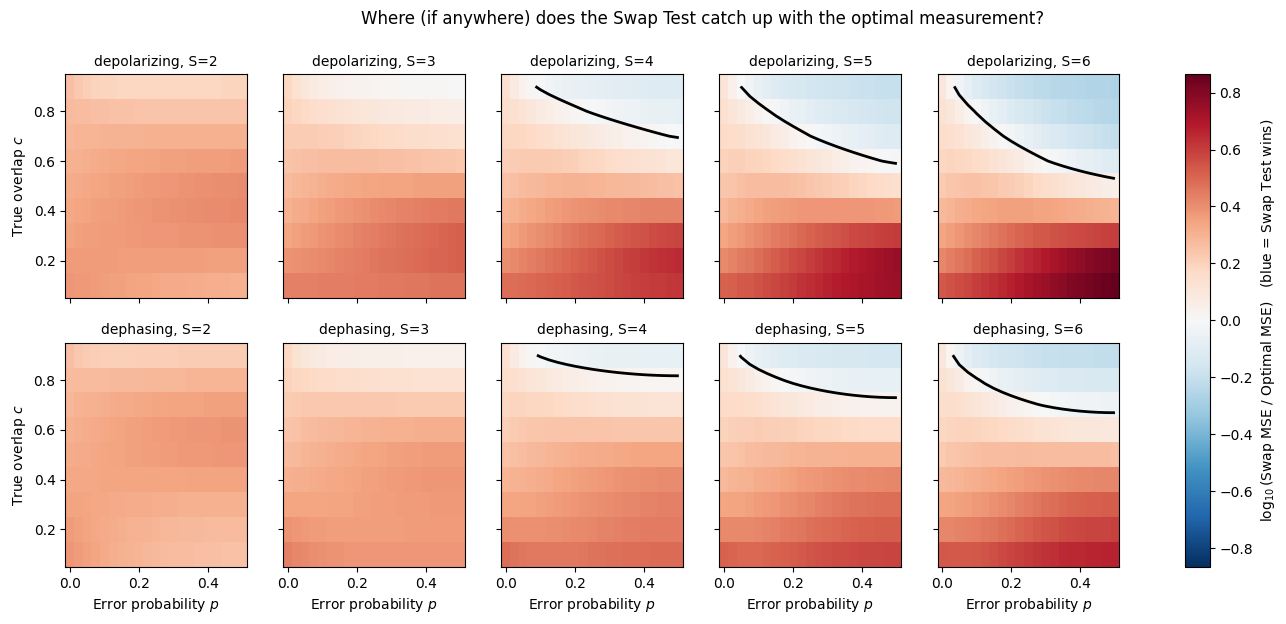

In [9]:
fig, axes = plt.subplots(len(NOISE_TYPES), len(S_all), figsize=(3.4 * len(S_all), 6.4), sharex=True, sharey=True)
vmax = max(np.abs(np.log10(gap(nt, S))).max() for nt in NOISE_TYPES for S in S_all)
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

for r, nt in enumerate(NOISE_TYPES):
    for k, S in enumerate(S_all):
        ax = axes[r, k]
        g = np.log10(gap(nt, S))
        im = ax.pcolormesh(p_grid, c_grid, g, cmap="RdBu_r", norm=norm, shading="auto")
        if (g <= 0).any():
            ax.contour(p_grid, c_grid, g, levels=[0], colors="black", linewidths=2)
        ax.set_title(f"{nt}, S={S}", fontsize=10)
        if r == len(NOISE_TYPES) - 1:
            ax.set_xlabel("Error probability $p$")
        if k == 0:
            ax.set_ylabel("True overlap $c$")

fig.colorbar(im, ax=axes, label=r"$\log_{10}$(Swap MSE / Optimal MSE)   (blue = Swap Test wins)")
fig.suptitle("Where (if anywhere) does the Swap Test catch up with the optimal measurement?")
plt.savefig("sweep_gap_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.2 Noiseless gap vs. S and vs. overlap

Left: noiseless gap as a function of $c$ for each $S$, against the asymptotic ratio $(1+c)/(2c)$ predicted by the paper. Right: noiseless gap vs. $S$ for three overlaps, converging to their respective asymptotes (dashed). Note how the intrinsic advantage of the collective measurement **vanishes as $c\to1$** (asymptotic ratio $\to1$): that is where it has the least margin against any extra noise penalty.

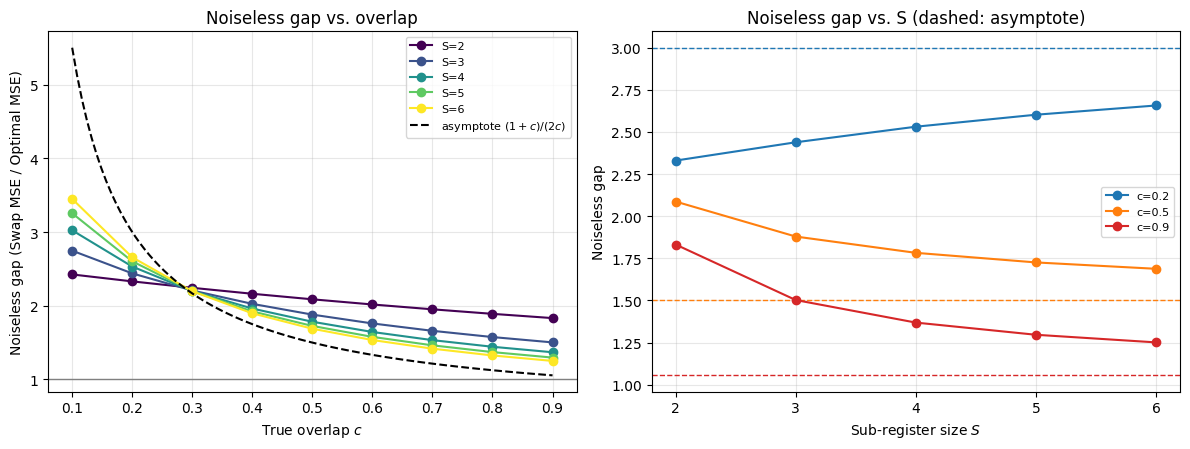

Noiseless gap table (rows: c, columns: S):
c     S=2       S=3       S=4       S=5       S=6       asymptote
0.1   2.424     2.747     3.023     3.254     3.449     5.500
0.2   2.330     2.439     2.531     2.602     2.657     3.000
0.3   2.243     2.207     2.200     2.197     2.196     2.167
0.4   2.162     2.025     1.961     1.923     1.897     1.750
0.5   2.087     1.879     1.783     1.726     1.688     1.500
0.6   2.017     1.760     1.644     1.578     1.534     1.333
0.7   1.951     1.660     1.533     1.463     1.417     1.214
0.8   1.890     1.575     1.443     1.371     1.325     1.125
0.9   1.832     1.503     1.369     1.296     1.251     1.056


In [10]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.6))
cmap = plt.get_cmap("viridis")
for k, S in enumerate(S_all):
    axL.plot(c_grid, gap("depolarizing", S)[:, 0], "o-", color=cmap(k / max(1, len(S_all) - 1)), label=f"S={S}")
c_dense = np.linspace(0.1, 0.9, 100)
axL.plot(c_dense, (1 + c_dense) / (2 * c_dense), "k--", label=r"asymptote $(1+c)/(2c)$")
axL.axhline(1.0, color="gray", lw=1)
axL.set_xlabel("True overlap $c$")
axL.set_ylabel("Noiseless gap (Swap MSE / Optimal MSE)")
axL.set_title("Noiseless gap vs. overlap")
axL.grid(alpha=0.3)
axL.legend(fontsize=8)

for c_sel, col in zip([0.2, 0.5, 0.9], ["tab:blue", "tab:orange", "tab:red"]):
    ic = int(np.argmin(np.abs(c_grid - c_sel)))
    axR.plot(S_all, [gap("depolarizing", S)[ic, 0] for S in S_all], "o-", color=col, label=f"c={c_sel}")
    axR.axhline((1 + c_sel) / (2 * c_sel), color=col, ls="--", lw=1)
axR.set_xlabel("Sub-register size $S$")
axR.set_ylabel("Noiseless gap")
axR.set_title("Noiseless gap vs. S (dashed: asymptote)")
axR.set_xticks(S_all)
axR.grid(alpha=0.3)
axR.legend(fontsize=8)
plt.tight_layout()
plt.savefig("noiseless_gap_vs_S_and_c.png", dpi=150)
plt.show()

print("Noiseless gap table (rows: c, columns: S):")
print(f"{'c':<6}" + "".join(f"S={S:<8}" for S in S_all) + "asymptote")
for i, c in enumerate(c_grid):
    print(f"{c:<6}" + "".join(f"{gap('depolarizing', S)[i, 0]:<10.3f}" for S in S_all) + f"{(1 + c) / (2 * c):.3f}")

### 7.3 Crossing threshold $p^*$: how much noise is needed for the Swap Test to win?

For each overlap and each $S$, $p^*$ is the smallest noise level (linear interpolation on the $p$ grid) at which the gap reaches 1. A missing point means **no crossing for $p\le0.5$**. If $p^*$ decreases with $S$, the crossing region moves toward more realistic noise levels as the sub-register grows.

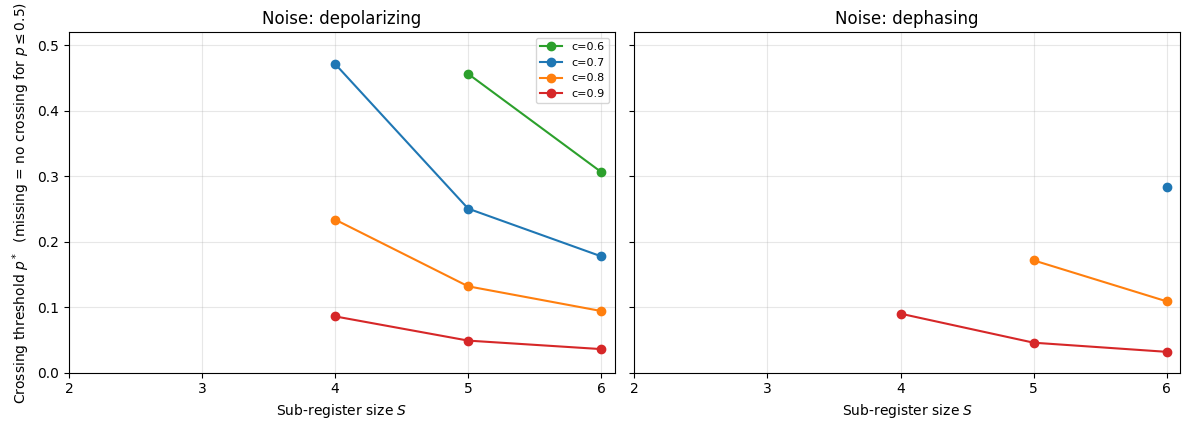


Crossing threshold p*  [depolarizing]   (nan = no crossing for p <= 0.5)
c     S=2       S=3       S=4       S=5       S=6       
0.6   nan       nan       nan       0.457     0.307     
0.7   nan       nan       0.472     0.251     0.178     
0.8   nan       nan       0.234     0.132     0.094     
0.9   nan       nan       0.086     0.049     0.036     

Crossing threshold p*  [dephasing]   (nan = no crossing for p <= 0.5)
c     S=2       S=3       S=4       S=5       S=6       
0.6   nan       nan       nan       nan       nan       
0.7   nan       nan       nan       nan       0.284     
0.8   nan       nan       nan       0.172     0.109     
0.9   nan       nan       0.090     0.046     0.032     


In [11]:
def crossing_threshold(gap_row):
    idx = np.where(gap_row <= 1.0)[0]
    if len(idx) == 0:
        return np.nan
    j = idx[0]
    if j == 0:
        return float(p_grid[0])
    g0, g1 = gap_row[j - 1], gap_row[j]
    return float(p_grid[j - 1] + (1 - g0) / (g1 - g0) * (p_grid[j] - p_grid[j - 1]))


c_focus = [0.6, 0.7, 0.8, 0.9]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, nt in zip(axes, NOISE_TYPES):
    for c_sel, col in zip(c_focus, ["tab:green", "tab:blue", "tab:orange", "tab:red"]):
        ic = int(np.argmin(np.abs(c_grid - c_sel)))
        ps = [crossing_threshold(gap(nt, S)[ic, :]) for S in S_all]
        ax.plot(S_all, ps, "o-", color=col, label=f"c={c_sel}")
    ax.set_title(f"Noise: {nt}")
    ax.set_xlabel("Sub-register size $S$")
    ax.set_xticks(S_all)
    ax.set_ylim(0, 0.52)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Crossing threshold $p^*$  (missing = no crossing for $p\\leq0.5$)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("crossing_threshold_vs_S.png", dpi=150)
plt.show()

for nt in NOISE_TYPES:
    print(f"\nCrossing threshold p*  [{nt}]   (nan = no crossing for p <= 0.5)")
    print(f"{'c':<6}" + "".join(f"S={S:<8}" for S in S_all))
    for c_sel in c_focus:
        ic = int(np.argmin(np.abs(c_grid - c_sel)))
        print(f"{c_sel:<6}" + "".join(f"{crossing_threshold(gap(nt, S)[ic, :]):<10.3f}" for S in S_all))

### 7.4 Summary: crossing region for every S

In [12]:
print(f"{'noise':<14}{'S':<4}{'#crossing pts':<15}{'of':<6}{'c range':<12}{'min p':<8}{'best gap (min)'}")
summary = {}
for nt in NOISE_TYPES:
    for S in S_all:
        g = gap(nt, S)
        mask = g <= 1.0
        n_cr = int(mask.sum())
        summary[(nt, S)] = n_cr
        if n_cr:
            ic, ip = np.where(mask)
            print(f"{nt:<14}{S:<4}{n_cr:<15}{g.size:<6}{c_grid[ic].min():.1f}-{c_grid[ic].max():.1f}{'':<4}{p_grid[ip].min():<8.3f}{g.min():.3f}x")
        else:
            print(f"{nt:<14}{S:<4}{0:<15}{g.size:<6}{'-':<12}{'-':<8}{g.min():.3f}x")

noise         S   #crossing pts  of    c range     min p   best gap (min)
depolarizing  2   0              189   -           -       1.531x
depolarizing  3   0              189   -           -       1.013x
depolarizing  4   30             189   0.7-0.9    0.100   0.766x
depolarizing  5   46             189   0.6-0.9    0.050   0.628x
depolarizing  6   57             189   0.6-0.9    0.050   0.542x
dephasing     2   0              189   -           -       1.614x
dephasing     3   0              189   -           -       1.111x
dephasing     4   17             189   0.9-0.9    0.100   0.852x
dephasing     5   33             189   0.8-0.9    0.050   0.706x
dephasing     6   44             189   0.7-0.9    0.050   0.615x


## 8. Robustness check


$$\text{gap}_F=\frac{1/F_\text{swap}}{1/F_\text{opt}}=\frac{F_\text{opt}}{F_\text{swap}}\qquad(\text{gap}_F>1:\text{ the optimal measurement carries more information about }c)$$

Here "optimal measurement" always means the $J$-projective measurement that is optimal in the noiseless case; for noisy (mixed) states a different collective measurement could in principle do better, which is not explored here.

### 8.1 Bias / variance decomposition at representative points

In [13]:
def opt_moments(c, S, p, noise_type):
    n = 2 * S
    probs = J_distribution(c, S, p, noise_type)
    mean = sum(pj * (2 * J / n) ** 2 for J, pj in probs.items())
    var = sum(pj * (2 * J / n) ** 4 for J, pj in probs.items()) - mean ** 2
    return mean, var


def swap_moments(c, S, p, noise_type):
    p0 = swap_p0(c, p, noise_type)
    return 2 * p0 - 1, 4 * p0 * (1 - p0) / S


print(f"{'noise':<14}{'c':<5}{'p':<5}{'S':<3}| {'Swap bias^2':<12}{'Swap var':<10}| {'Opt bias^2':<12}{'Opt var':<10}| MSE ratio (swap/opt)")
for nt in NOISE_TYPES:
    for c, p in [(0.9, 0.0), (0.9, 0.1), (0.9, 0.3), (0.7, 0.3)]:
        for S in [4, 6]:
            sm, sv = swap_moments(c, S, p, nt)
            om, ov = opt_moments(c, S, p, nt)
            sb, ob = (sm - c) ** 2, (om - c) ** 2
            print(f"{nt:<14}{c:<5}{p:<5}{S:<3}| {sb:<12.4f}{sv:<10.4f}| {ob:<12.4f}{ov:<10.4f}| {(sb + sv) / (ob + ov):.3f}")

noise         c    p    S  | Swap bias^2 Swap var  | Opt bias^2  Opt var   | MSE ratio (swap/opt)
depolarizing  0.9  0.0  4  | 0.0000      0.0475    | 0.0002      0.0345    | 1.369


depolarizing  0.9  0.0  6  | 0.0000      0.0317    | 0.0001      0.0252    | 1.251
depolarizing  0.9  0.1  4  | 0.0099      0.0898    | 0.0237      0.0790    | 0.972


depolarizing  0.9  0.1  6  | 0.0099      0.0599    | 0.0310      0.0588    | 0.778
depolarizing  0.9  0.3  4  | 0.0655      0.1463    | 0.1684      0.0937    | 0.808


depolarizing  0.9  0.3  6  | 0.0655      0.0975    | 0.2124      0.0657    | 0.586
depolarizing  0.7  0.3  4  | 0.0164      0.1682    | 0.0729      0.0881    | 1.146


depolarizing  0.7  0.3  6  | 0.0164      0.1121    | 0.1049      0.0601    | 0.779
dephasing     0.9  0.0  4  | 0.0000      0.0475    | 0.0002      0.0345    | 1.369


dephasing     0.9  0.0  6  | 0.0000      0.0317    | 0.0001      0.0252    | 1.251
dephasing     0.9  0.1  4  | 0.0207      0.1071    | 0.0427      0.0872    | 0.984


dephasing     0.9  0.1  6  | 0.0207      0.0714    | 0.0545      0.0644    | 0.775
dephasing     0.9  0.3  4  | 0.1129      0.1705    | 0.2420      0.0842    | 0.869


dephasing     0.9  0.3  6  | 0.1129      0.1137    | 0.3010      0.0562    | 0.634
dephasing     0.7  0.3  4  | 0.0282      0.1792    | 0.0657      0.0856    | 1.371


dephasing     0.7  0.3  6  | 0.0282      0.1195    | 0.0923      0.0577    | 0.985


**Reading the table:** in the crossing region the optimal measurement still has the **lower variance** (e.g. $c=0.9$, $p=0.3$, $S=6$), but a much **larger bias$^2$**: noise shifts the $J$-distribution toward lower $J$ and the noiseless-calibrated estimator $(2J/2S)^2$ systematically underestimates $c$. The crossing seen in Section 7 is therefore largely bias-driven, i.e. a property of the *uncalibrated estimator*, not of the information the measurement extracts.

### 8.2 Noise-aware comparison via Fisher information

Same $(c,p)$ sweep (coarser noise grid, $p$ step 0.05, to bound the run time). Points where either measurement carries no information about $c$ (e.g. full dephasing, $p=0.5$, of a state on the equator of the Bloch sphere) are shown blank.

In [14]:
def fisher_swap(c, S, p, noise_type, h=0.01):
    """Fisher information of S independent Swap Test trials (outcome ~ Bernoulli(p0(c)))."""
    q = swap_p0(c, p, noise_type)
    dq = (swap_p0(c + h, p, noise_type) - swap_p0(c - h, p, noise_type)) / (2 * h)
    return S * dq ** 2 / (q * (1 - q))


def fisher_opt(c, S, p, noise_type, h=0.01):
    """Fisher information of the J-measurement outcome distribution p(J | c)."""
    P0 = J_distribution(c, S, p, noise_type)
    Pp = J_distribution(c + h, S, p, noise_type)
    Pm = J_distribution(c - h, S, p, noise_type)
    return sum(((Pp.get(J, 0.0) - Pm.get(J, 0.0)) / (2 * h)) ** 2 / v for J, v in P0.items() if v > 1e-14)


p_fi = np.linspace(0.0, 0.5, 11)
gap_fi = {nt: {} for nt in NOISE_TYPES}

for S in S_all:
    for nt in NOISE_TYPES:
        g = np.full((len(c_grid), len(p_fi)), np.nan)
        for ic, c in enumerate(c_grid):
            for ip, p in enumerate(p_fi):
                fs = fisher_swap(float(c), S, float(p), nt)
                fo = fisher_opt(float(c), S, float(p), nt)
                if fs > 1e-12 and fo > 1e-12:
                    g[ic, ip] = fo / fs
        gap_fi[nt][S] = g
    print(f"S={S}: Fisher-information sweep done")

print()
print("Sanity check (noiseless): Fisher gap vs. the paper's asymptotic ratio (1+c)/(2c)")
print(f"{'c':<6}" + "".join(f"S={S:<8}" for S in S_all) + "asymptote")
for c_sel in [0.2, 0.5, 0.9]:
    ic = int(np.argmin(np.abs(c_grid - c_sel)))
    print(f"{c_sel:<6}" + "".join(f"{gap_fi['depolarizing'][S][ic, 0]:<10.3f}" for S in S_all) + f"{(1 + c_sel) / (2 * c_sel):.3f}")

S=2: Fisher-information sweep done


S=3: Fisher-information sweep done


S=4: Fisher-information sweep done


S=5: Fisher-information sweep done


S=6: Fisher-information sweep done

Sanity check (noiseless): Fisher gap vs. the paper's asymptotic ratio (1+c)/(2c)
c     S=2       S=3       S=4       S=5       S=6       asymptote
0.2   1.522     1.854     2.081     2.245     2.366     3.000
0.5   1.231     1.330     1.380     1.409     1.427     1.500
0.9   1.035     1.044     1.047     1.049     1.050     1.056


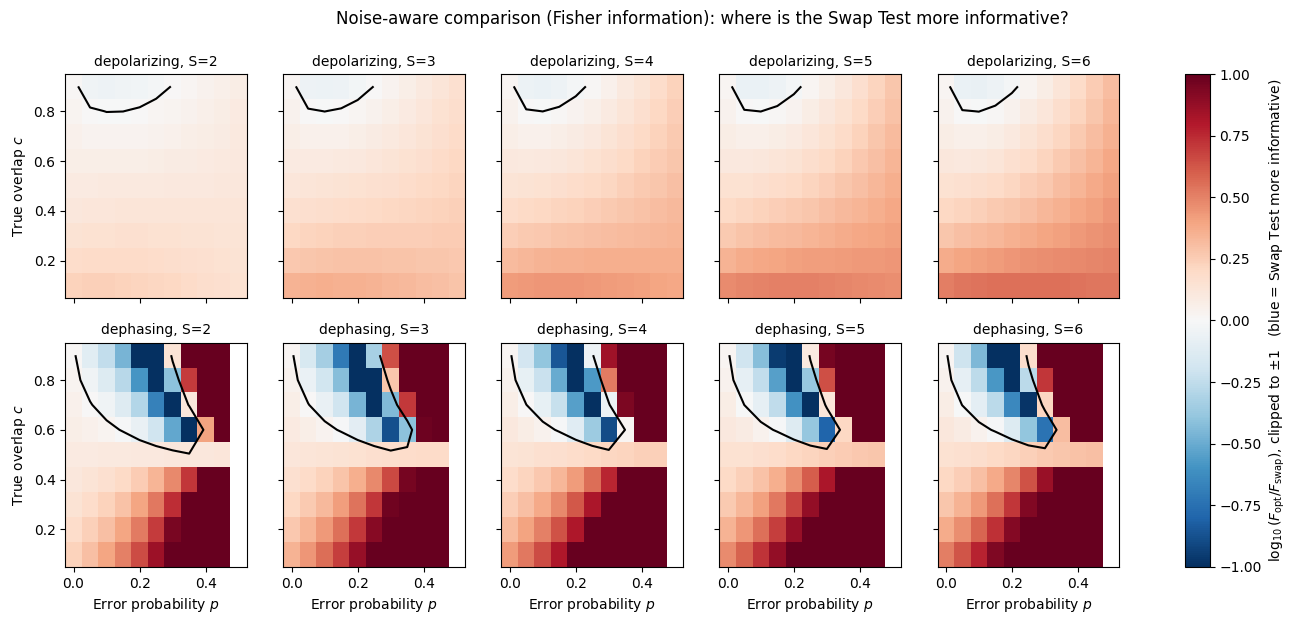

In [15]:
fig, axes = plt.subplots(len(NOISE_TYPES), len(S_all), figsize=(3.4 * len(S_all), 6.4), sharex=True, sharey=True)
CLIP = 1.0  # colour scale clipped to gap in [0.1, 10] for readability
norm = TwoSlopeNorm(vmin=-CLIP, vcenter=0.0, vmax=CLIP)
for r, nt in enumerate(NOISE_TYPES):
    for k, S in enumerate(S_all):
        ax = axes[r, k]
        g = np.log10(gap_fi[nt][S])
        im = ax.pcolormesh(p_fi, c_grid, np.ma.masked_invalid(g), cmap="RdBu_r", norm=norm, shading="auto")
        if np.nanmin(g) <= 0:
            ax.contour(p_fi, c_grid, np.nan_to_num(g, nan=1.0), levels=[0], colors="black", linewidths=1.5)
        ax.set_title(f"{nt}, S={S}", fontsize=10)
        if r == len(NOISE_TYPES) - 1:
            ax.set_xlabel("Error probability $p$")
        if k == 0:
            ax.set_ylabel("True overlap $c$")
fig.colorbar(im, ax=axes, label=r"$\log_{10}(F_\mathrm{opt}/F_\mathrm{swap})$, clipped to $\pm1$   (blue = Swap Test more informative)")
fig.suptitle("Noise-aware comparison (Fisher information): where is the Swap Test more informative?")
plt.savefig("sweep_gap_heatmaps_fisher.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
print(f"{'noise':<14}{'S':<4}{'#pts gap_F<1':<14}{'of':<5}{'c range':<11}{'p range':<12}{'min gap_F':<11}{'max gap_F'}")
for nt in NOISE_TYPES:
    for S in S_all:
        g = gap_fi[nt][S]
        valid = np.isfinite(g)
        mask = valid & (g < 1.0)
        n_cr = int(mask.sum())
        if n_cr:
            ic, ip = np.where(mask)
            print(f"{nt:<14}{S:<4}{n_cr:<14}{int(valid.sum()):<5}{c_grid[ic].min():.1f}-{c_grid[ic].max():.1f}{'':<3}{p_fi[ip].min():.2f}-{p_fi[ip].max():.2f}{'':<3}{np.nanmin(g):<11.3f}{np.nanmax(g):.2f}")
        else:
            print(f"{nt:<14}{S:<4}{0:<14}{int(valid.sum()):<5}{'-':<11}{'-':<12}{np.nanmin(g):<11.3f}{np.nanmax(g):.2f}")

print()
print("Depolarizing: noise-aware gap vs S at selected (c, p)  (rows) x S (columns)")
print(f"{'(c, p)':<12}" + "".join(f"S={S:<7}" for S in S_all))
for c_sel, p_sel in [(0.9, 0.1), (0.9, 0.3), (0.9, 0.5), (0.7, 0.3), (0.5, 0.3), (0.2, 0.3)]:
    ic = int(np.argmin(np.abs(c_grid - c_sel)))
    ip = int(np.argmin(np.abs(p_fi - p_sel)))
    print(f"{str((c_sel, p_sel)):<12}" + "".join(f"{gap_fi['depolarizing'][S][ic, ip]:<9.2f}" for S in S_all))

print()
corner = [np.nanmin(gap_fi['depolarizing'][S]) for S in S_all]
print("Depolarizing: minimum noise-aware gap on the grid, S=2..6:", np.round(corner, 3),
      "-> step sizes:", np.round(np.diff(corner), 3))

noise         S   #pts gap_F<1  of   c range    p range     min gap_F  max gap_F
depolarizing  2   7             99   0.8-0.9   0.05-0.25   0.894      1.72
depolarizing  3   5             99   0.8-0.9   0.05-0.20   0.869      2.29
depolarizing  4   5             99   0.8-0.9   0.05-0.20   0.858      2.77
depolarizing  5   5             99   0.8-0.9   0.05-0.20   0.851      3.19
depolarizing  6   5             99   0.8-0.9   0.05-0.20   0.846      3.59
dephasing     2   21            90   0.6-0.9   0.05-0.35   0.004      2147.27
dephasing     3   20            90   0.6-0.9   0.05-0.35   0.004      4818.85
dephasing     4   19            90   0.6-0.9   0.05-0.30   0.014      7225.03
dephasing     5   18            90   0.6-0.9   0.05-0.30   0.036      9331.33
dephasing     6   18            90   0.6-0.9   0.05-0.30   0.032      11172.90

Depolarizing: noise-aware gap vs S at selected (c, p)  (rows) x S (columns)
(c, p)      S=2      S=3      S=4      S=5      S=6      
(0.9, 0.1)  0.89  

### 8.3 Why the dephasing results must be read with care

Depolarizing noise is isotropic, so it does not matter how the two states are oriented: the noisy states only depend on the overlap $c$ (plus a fixed Bloch-vector shrinkage), and the results are generic. **Dephasing is not isotropic**: it acts along the $z$ axis, so its effect depends on how $|\psi\rangle$ and $|\phi\rangle$ sit relative to that axis. In our setup $|\psi\rangle=R_Y(\pi/2)|0\rangle$ lies on the equator (the *worst case* for $z$-dephasing: at $p=0.5$ it is completely erased), and, as the check below shows, the **purity of the noisy $|\phi\rangle$ changes with $c$**. The family of noisy states therefore varies in more than the overlap, which makes the information about $c$ carried by each measurement fluctuate strongly (hence the erratic dephasing values of $\text{gap}_F$, including points where one measurement carries almost no information). The dephasing results are thus specific to this orientation and should not be extrapolated to generic states.

In [17]:
print("Bloch-vector length of the noisy |phi> at p=0.3 (1 = pure) as a function of the overlap c")
print(f"{'c':<6}{'depolarizing':<15}{'dephasing'}")
for c_sel in [0.1, 0.3, 0.5, 0.7, 0.9]:
    row = []
    for nt in NOISE_TYPES:
        R = single_qubit_state(PSI_OFFSET + delta_from_c(c_sel), 0.3, nt)
        x, y, z = 2 * R[0, 1], 0.0, R[0, 0] - R[1, 1]
        row.append(float(np.sqrt(x ** 2 + y ** 2 + z ** 2)))
    print(f"{c_sel:<6}{row[0]:<15.3f}{row[1]:.3f}")

Bloch-vector length of the noisy |phi> at p=0.3 (1 = pure) as a function of the overlap c
c     depolarizing   dephasing
0.1   0.600          0.680
0.3   0.600          0.930
0.5   0.600          1.000
0.7   0.600          0.930
0.9   0.600          0.680


## 9. Final conclusion


- **Reference point** ($c=0.2$, noiseless): the MSE gap grew with $S$ ($2.33\to2.44\to2.53$ for $S=2,3,4$; $2.60$ and $2.66$ for $S=5,6$), approaching the paper's asymptote of $3.0$. Judged at this single point, the rule says "stop".
- **Point-wise rule over the $(c,p)$ grid:** the gap shrinks between $S=3$ and $S=4$ at 127/189 (depolarizing) and 112/189 (dephasing) grid points, so the extension to $S=5,6$ was **triggered** and run. Part of that shrinkage is noiseless: for $c\\ge0.3$ the noiseless gap decreases with $S$ but converges from above to $(1+c)/(2c)>1$ (e.g. $c=0.9$: $1.83,1.50,1.37,1.30,1.25\\to1.056$). So "the gap grows with $S$" holds only for small overlaps ($c\\lesssim0.2$); for larger $c$ it decreases toward a floor that stays above 1.
